# Exploratory data analysis — flights dataset

100,000 synthetic international flights generated by `code/dataset_extended.py` from OpenFlights routes, airports and airlines. Price depends on distance, cabin class, region and season.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/flights_dataset_100000.csv.xz')
print(df.shape)
df.head()

(100000, 25)


,flight_number,airline,airline_code,airline_country,origin_airport,origin_city,origin_country,dest_airport,dest_city,dest_country,...,duration_hours,stops,cabin_class,fare_type,price_usd,seats_available,aircraft_type,departure_time,flight_category,month
0,YK2808,Cyprus Turkish Airlines,YK,Turkey,OVB,Novosibirsk,Russia,FRU,Bishkek,Kyrgyzstan,...,2.50,0,Economy,Flexible,276.07,53,146,23:15,Moyen-courrier (500-2000 km),5
1,UY6784,Cameroon Airlines,UY,Cameroon,TBS,Tbilisi,Georgia,BGW,Baghdad,Iraq,...,1.98,0,Economy,Non-Refundable,175.19,72,M83,12:15,Moyen-courrier (500-2000 km),7
2,W68534,Wizz Air,W6,Hungary,GLA,Glasgow,United Kingdom,GDN,Gdansk,Poland,...,2.83,0,Business,Full-Fare,1100.18,41,320,07:15,Moyen-courrier (500-2000 km),12
3,LH8106,Lufthansa Cargo,LH,Germany,NUE,Nuernberg,Germany,ZRH,Zurich,Switzerland,...,1.10,0,Economy,Semi-Flexible,94.45,91,AR1 100,20:15,Court-courrier (< 500 km),3
4,TR231,Tiger Airways,TR,Singapore,SIN,Singapore,Singapore,CRK,Angeles City,Philippines,...,3.86,0,Economy,Non-Refundable,190.34,60,320,13:45,Long-courrier (2000-6000 km),10


In [2]:
df.isna().sum().sum(), df.duplicated().sum()

(np.int64(0), np.int64(0))

In [3]:
df['price_usd'].describe().round(2)

count    100000.00
mean        549.63
std         855.42
min          50.00
25%         177.88
50%         298.27
75%         574.88
max       18620.71
Name: price_usd, dtype: float64

## Price distribution
Prices are right-skewed, so the models learn `log1p(price)`.

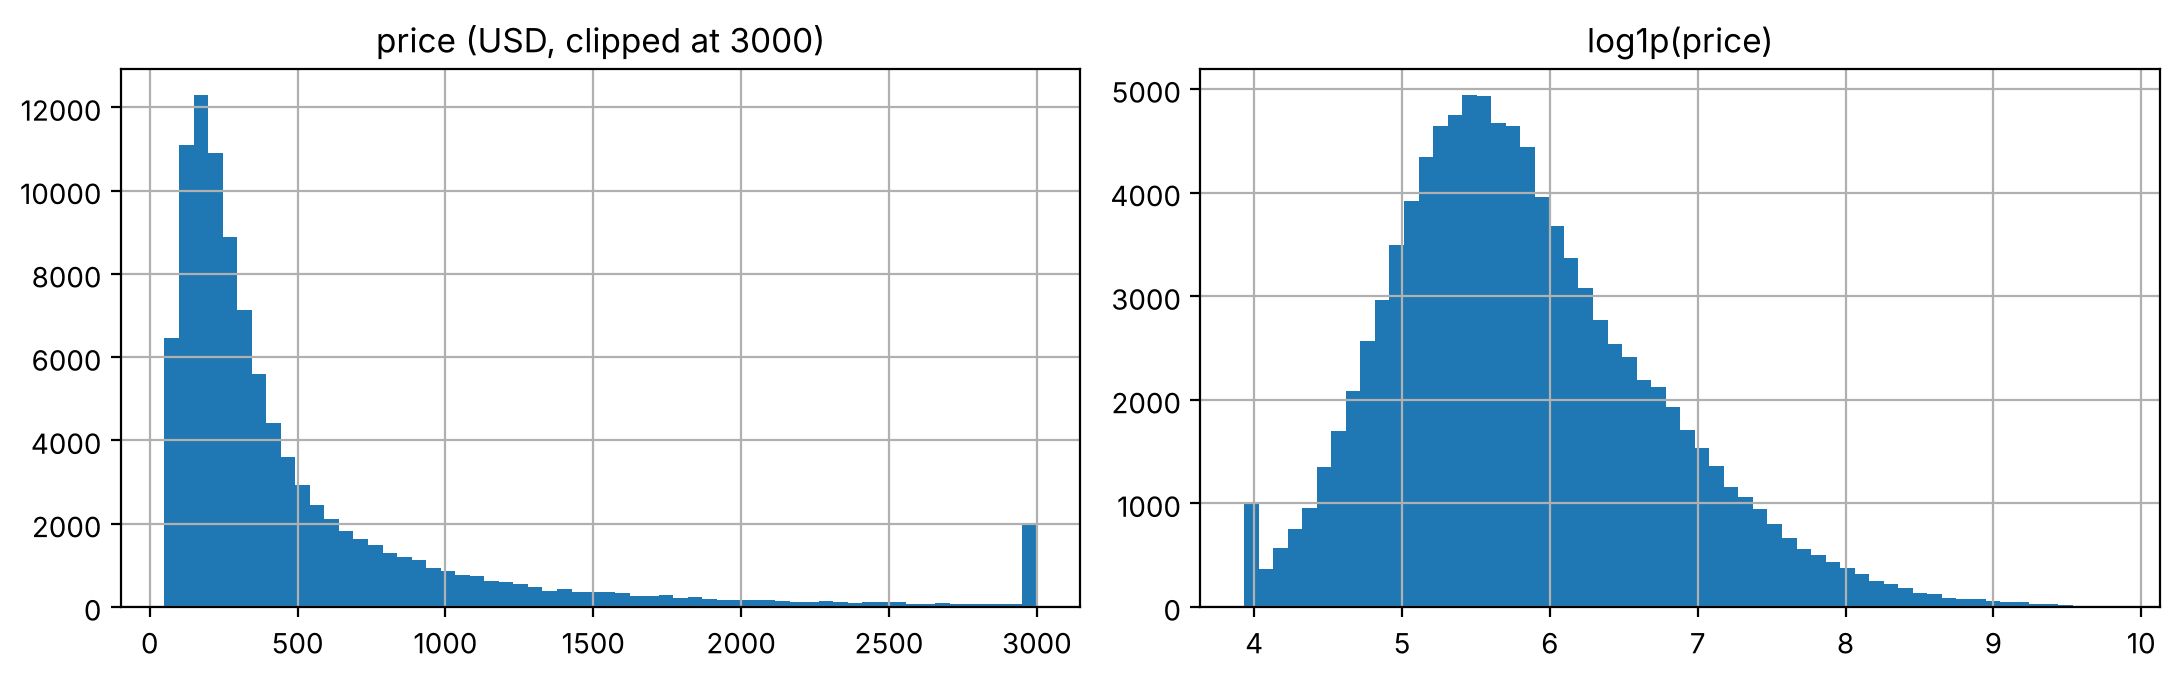

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df['price_usd'].clip(upper=3000).hist(bins=60, ax=ax[0]); ax[0].set_title('price (USD, clipped at 3000)')
import numpy as np
np.log1p(df['price_usd']).hist(bins=60, ax=ax[1]); ax[1].set_title('log1p(price)')
plt.tight_layout()

## Price vs distance
Distance is a key driver of price (correlation ≈ 0.45); cabin class and season then multiply it.

correlation: 0.447


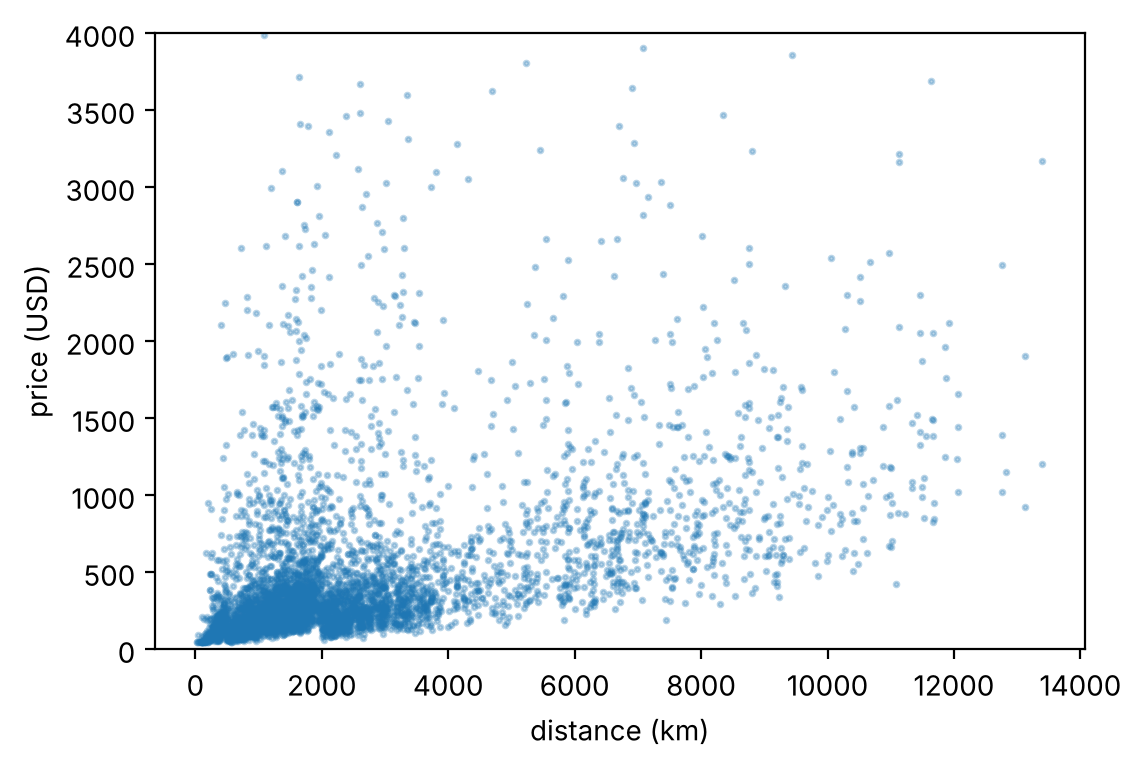

In [5]:
s = df.sample(5000, random_state=0)
plt.figure(figsize=(6, 4))
plt.scatter(s['distance_km'], s['price_usd'], s=3, alpha=0.3)
plt.xlabel('distance (km)'); plt.ylabel('price (USD)'); plt.ylim(0, 4000)
print('correlation:', round(df['distance_km'].corr(df['price_usd']), 3))

## Cabin class and season

In [6]:
df.groupby('cabin_class')['price_usd'].median().sort_values().round(1)

cabin_class
Economy             237.3
Premium Economy     381.3
Business            821.1
First              1888.6
Name: price_usd, dtype: float64

<Axes: title={'center': 'median price by month'}, xlabel='month'>

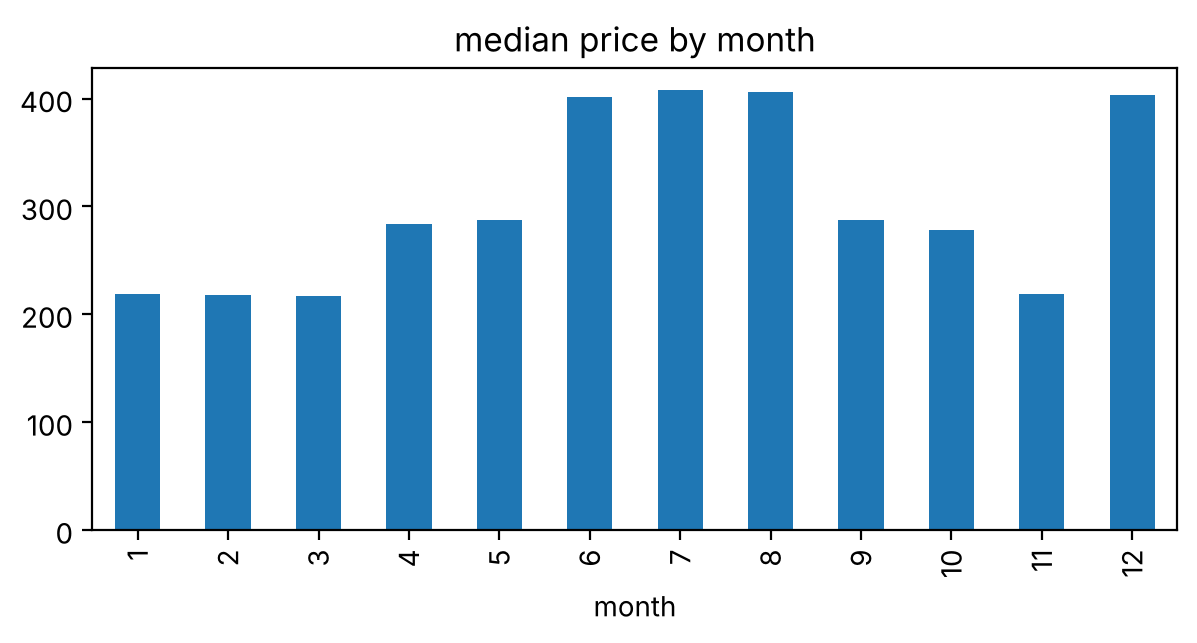

In [7]:
df.groupby('month')['price_usd'].median().round(1).plot(kind='bar', figsize=(7, 3), title='median price by month')

In [8]:
df['flight_category'].value_counts()

flight_category
Moyen-courrier (500-2000 km)       48203
Long-courrier (2000-6000 km)       32580
Ultra long-courrier (> 6000 km)    12117
Court-courrier (< 500 km)           7100
Name: count, dtype: int64

In [9]:
df.groupby('fare_type')['price_usd'].median().round(1)

fare_type
Flexible          299.5
Full-Fare         301.2
Non-Refundable    297.6
Semi-Flexible     298.1
Name: price_usd, dtype: float64

## Takeaways
- Distance, cabin class (First ≈ 8× Economy in median) and season (June–August and December are more expensive) drive the price.
- Fare type has almost no effect on price in this synthetic dataset.
- The target is skewed: train on `log1p(price)` and report errors back in USD.
- Categorical features with many values (airline, countries) are ordinal-encoded for tree models and one-hot encoded for the linear baseline.